In [1]:
!pip install pandas numpy matplotlib

In [2]:
import os, re, sys, json, csv, gzip, string
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
trainer_state_data = []
file_path = "/content/drive/MyDrive/CAISI_phase2/safe-finetuning/LoRA/outputs/llama_alpaca/checkpoint-1330/trainer_state.json"
with open(file_path, 'r') as file:
  data = json.load(file)

df = pd.json_normalize(data, record_path=["log_history"])

In [4]:
df

,entropy,epoch,grad_norm,learning_rate,loss,mean_token_accuracy,num_tokens,step,eval_entropy,eval_loss,eval_mean_token_accuracy,eval_num_tokens,eval_runtime,eval_samples_per_second,eval_steps_per_second
0,0.992134,0.003759,1.278964,0.000000e+00,1.9945,0.634208,3559.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.124578,0.037594,1.667731,2.686567e-05,2.1810,0.603489,31228.0,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.086144,0.075188,1.700046,5.671642e-05,1.8383,0.627027,65225.0,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.294557,0.112782,0.770956,8.656716e-05,1.6214,0.648950,94375.0,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.273756,0.150376,0.590637,1.164179e-04,1.2392,0.696079,123871.0,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
134,0.886906,4.887218,0.389928,4.908947e-06,0.8897,0.745180,4005559.0,1300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
135,0.852692,4.924812,0.372893,3.325416e-06,0.8409,0.757408,4036982.0,1310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
136,0.876893,4.962406,0.429008,1.741884e-06,0.8734,0.743885,4067948.0,1320,NaN,NaN,NaN,NaN,NaN,NaN,NaN
137,0.892483,5.000000,0.529946,1.583531e-07,0.9021,0.744677,4096470.0,1330,NaN,NaN,NaN,NaN,NaN,NaN,NaN


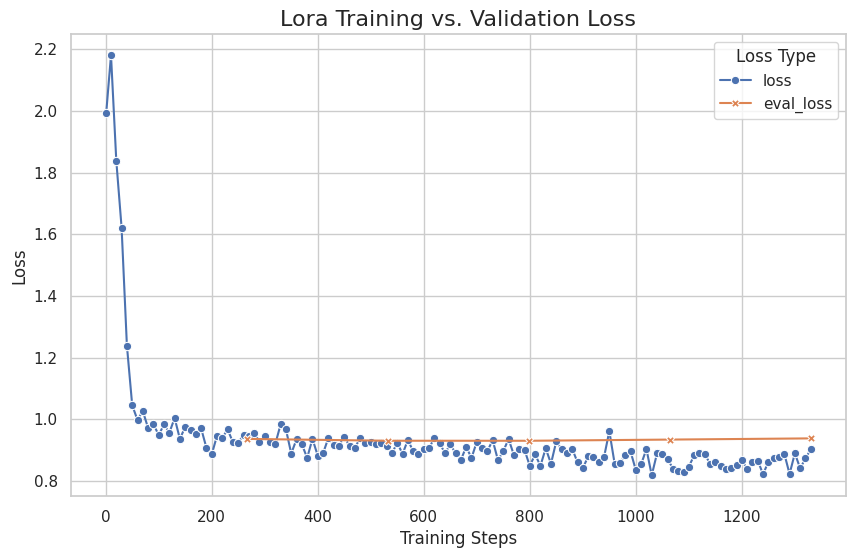

In [5]:
  log_history = pd.DataFrame(data.get("log_history", []))
  log_history = log_history[(log_history["loss"].notna()) | (log_history["eval_loss"].notna())]

  df_melted = log_history.melt(
      id_vars=["step"],
      value_vars=["loss", "eval_loss"],
      var_name="Loss Type",
      value_name="Loss"
  )

#Plot loss vs. steps

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10,6))
sns.lineplot(
    data=df_melted,
    x="step", y="Loss", hue="Loss Type",
    style="Loss Type", markers=True, dashes=False
)
plt.xlabel("Training Steps", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Lora Training vs. Validation Loss", fontsize=16)
plt.legend(title="Loss Type")
plt.show()